# Modèles de base 

Ce notebook implémente les étapes demandées pour la **Partie 3** du Jalon 2

## 1. Régression logistique par défaut

Nous allons entraîner une régression logistique de base sur l'ensemble d'entaînement.


In [34]:
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
from sklearn.linear_model import LogisticRegression
import joblib
from ift6758.data_acquisition import PROJECT_ROOT
from ift6758.features.build_dataset import PROCESSED
from pathlib import Path
import pandas as pd
import numpy as np

data_train_path = PROJECT_ROOT / "data" / PROCESSED / "train_set.csv"
data_val_path = PROJECT_ROOT / "data" / PROCESSED / "validation_set.csv"

train_all = pd.read_csv(data_train_path)
val_all = pd.read_csv(data_val_path)

# On retire les nan
train_clean = train_all.dropna(subset=["shot_distance", "is_goal"])
val_clean = val_all.dropna(subset=["shot_distance", "is_goal"])

# Definition de nos ensemble de donnees
X_train = train_clean[["shot_distance"]]
Y_train = train_clean["is_goal"]
X_val = val_clean[["shot_distance"]]
Y_val = val_clean["is_goal"]

clf_shot_dist = LogisticRegression(random_state=42)
clf_shot_dist.fit(X_train, Y_train)

Y_pred = clf_shot_dist.predict(X_val)
accuracy = accuracy_score(Y_val, Y_pred)

print(f"Accuracy sur l'ensemble de validation : {accuracy}")


Accuracy sur l'ensemble de validation : 0.9026960527194179


On voit que notre accuracy est très élevée, mais nous avons vu que l'accuracy n'est pas une bonne métrique quand les classes sont déséquilibrés. Pour confirmer nos doutes, nous allons regarder d'autres chiffres : 

In [27]:
print(f"Proportion réelle de non-buts : {(Y_val == 0).mean():.4f}")
print(f"Nombre de buts prédits par le modèle : {(Y_pred == 1).sum()} sur {len(Y_pred)}")

print("\nMatrice de confusion :")
print(confusion_matrix(Y_val, Y_pred))

Proportion réelle de non-buts : 0.9027
Nombre de buts prédits par le modèle : 0 sur 104857

Matrice de confusion :
[[94654     0]
 [10203     0]]


Avec ces chiffres, le problème est évident, comme la proportion réelle de non-buts est de 90.27%, alors le modèle entraîné prédit systématiquement la classe majoritaire ("non-but"). En effet, sur les 104857 tirs de l'ensemble de validation, il n'a prédit aucun but. En observant la matrice de confusion, nous constatons qu'il n'y a aucun faux positifs (le modèle a jamais prédit un but à tort), mais la totalité des 10203 buts ont été manqués (ce sont tous des faux négatifs). Le problème est évident : en raison du fort déséquilibre des classes, la métrique d'accuracy n'est pas adaptée, ce qui fait qu'un modèle naïf qui ne fait que prédire "non-but" atteint 0.90 d'accuracy sans rien apprendre.

## 2. Investiguation de la probabilité prédite

Pour commencer, nous allons faire le graphique (i) de la courbe ROC et AUC. 
Le but est de mesurer la capacité du modèle à classifier un tir qui est un but avec une probabilité plus élevée qu'un tir qui n'est pas un but.

c:\Users\carig\Documents\GitHub\IFT3700_Projet1\.venv\lib\site-packages\sklearn\utils\_plotting.py:175: FutureWarning: `**kwargs` is deprecated and will be removed in 1.9. Pass all matplotlib arguments to `curve_kwargs` as a dictionary instead.
  warnings.warn(


[Text(0.5, 0, 'Taux de Faux Positifs (FPR)'),
 Text(0, 0.5, 'Taux de Vrais Positifs (TPR)'),
 Text(0.5, 1.0, 'Courbe ROC pour la régression logistique')]

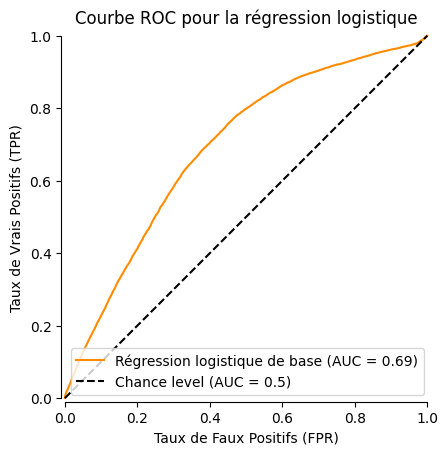

In [28]:
import matplotlib.pyplot as plt
from sklearn import metrics
import seaborn as sns
# On prend maintenant la probabilité que la classe soit = 1
Y_score_dist = clf_shot_dist.predict_proba(X_val)[:,1]

# Le code est inspiré des exemples de la documentation de sk-learn : https://scikit-learn.org/stable/auto_examples/model_selection/plot_roc.html

display = metrics.RocCurveDisplay.from_predictions(
    Y_val,
    Y_score_dist,
    name="Régression logistique de base",
    color="darkorange",
    plot_chance_level=True,
    despine=True
)

display.ax_.set(
    xlabel = "Taux de Faux Positifs (FPR)",
    ylabel = "Taux de Vrais Positifs (TPR)",
    title = "Courbe ROC pour la régression logistique"
)

c:\Users\carig\Documents\GitHub\IFT3700_Projet1\.venv\lib\site-packages\sklearn\utils\_plotting.py:175: FutureWarning: `**kwargs` is deprecated and will be removed in 1.9. Pass all matplotlib arguments to `curve_kwargs` as a dictionary instead.
  warnings.warn(


[Text(0.5, 0, 'Taux de Faux Positifs (FPR)'),
 Text(0, 0.5, 'Taux de Vrais Positifs (TPR)'),
 Text(0.5, 1.0, 'Courbe ROC pour la régression logistique')]

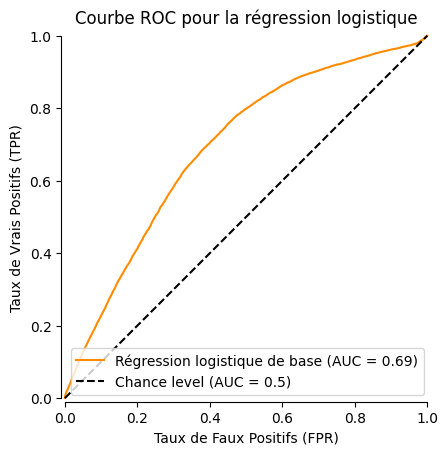

In [ ]:
import matplotlib.pyplot as plt
from sklearn import metrics
import seaborn as sns
# On prend maintenant la probabilité que la classe soit = 1
Y_score_dist = clf_shot_dist.predict_proba(X_val)[:,1]

# Le code est inspiré des exemples de la documentation de sk-learn : https://scikit-learn.org/stable/auto_examples/model_selection/plot_roc.html

display = metrics.RocCurveDisplay.from_predictions(
    Y_val,
    Y_score_dist,
    name="Régression logistique de base",
    color="darkorange",
    plot_chance_level=True,
    despine=True
)

display.ax_.set(
    xlabel = "Taux de Faux Positifs (FPR)",
    ylabel = "Taux de Vrais Positifs (TPR)",
    title = "Courbe ROC pour la régression logistique"
)

On remarque que la distance apporte un pouvoir prédictif au modèle par rapport au hasard malgré que le modèle est basique.

Maintenant, passons au graphique (ii) du taux de buts en fonction du centile de la probabilité de tir donnée par le modèle. 

c:\Users\carig\Documents\GitHub\IFT3700_Projet1\.venv\lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
c:\Users\carig\Documents\GitHub\IFT3700_Projet1\.venv\lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


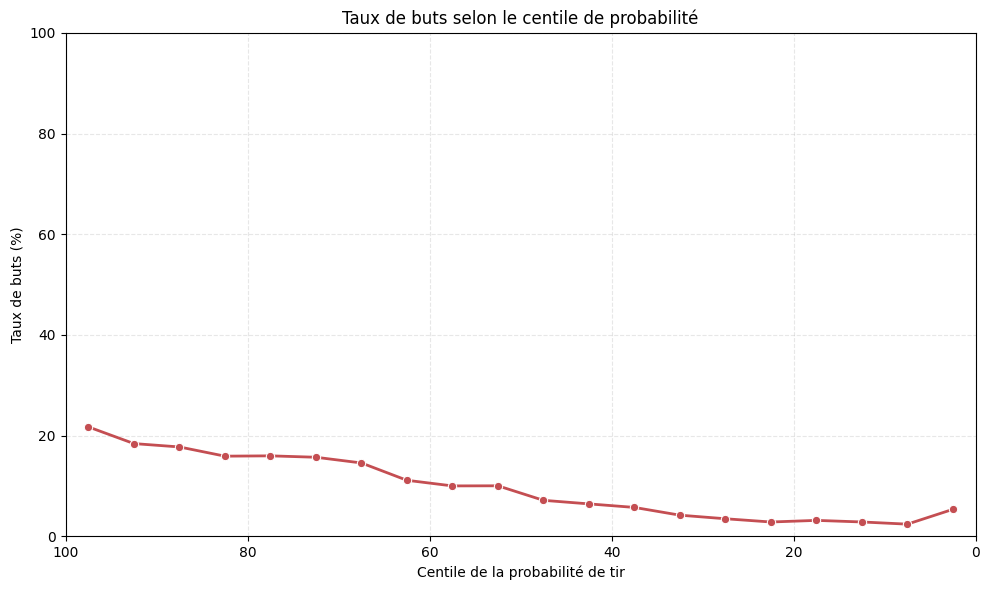

In [29]:
# On doit ajouter une colonne score_centile et ensuite séparer les données en 
# bins de centiles
X_graph = val_clean.copy()
X_graph["Y_score_prob"] = Y_score_dist
X_graph["centile_score"] = X_graph["Y_score_prob"].rank(pct=True) * 100
X_graph["centiles_bins"] = pd.cut(X_graph["centile_score"], 
                                            bins= list(range(0, 105, 5)), 
                                            include_lowest=True
                                            ).apply(lambda x: x.mid if pd.notna(x) else np.nan)

rate_per_centile = (X_graph.groupby("centiles_bins", observed=True)["is_goal"].agg(["mean", "count"]).reset_index())
rate_per_centile["mean"] = rate_per_centile["mean"]*100

fig, ax = plt.subplots(figsize=(10, 6))

sns.lineplot(
    data=rate_per_centile,
    x="centiles_bins",
    y="mean",
    marker="o",
    color="#C44E52",
    linewidth=2,
    ax=ax
)
ax.set_title("Taux de buts selon le centile de probabilité")
ax.set_xlabel("Centile de la probabilité de tir")
ax.invert_xaxis()
ax.set_xlim(100, 0) 
ax.set_ylabel("Taux de buts (%)")
ax.set_ylim(0, 100)
ax.grid(True, linestyle="--", alpha=0.3)
plt.tight_layout()
plt.show()

On remarque que comme la courbe est croissante en fonction du centile, alors le modèle réussit bien à classer les tirs par ordre de dangerosité réelle.

Passons maintenant au graphique (iii) qui est la proportion cumulée de buts en fonction du centile de la probabilité de tir donnée par le modèle.

c:\Users\carig\Documents\GitHub\IFT3700_Projet1\.venv\lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
c:\Users\carig\Documents\GitHub\IFT3700_Projet1\.venv\lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


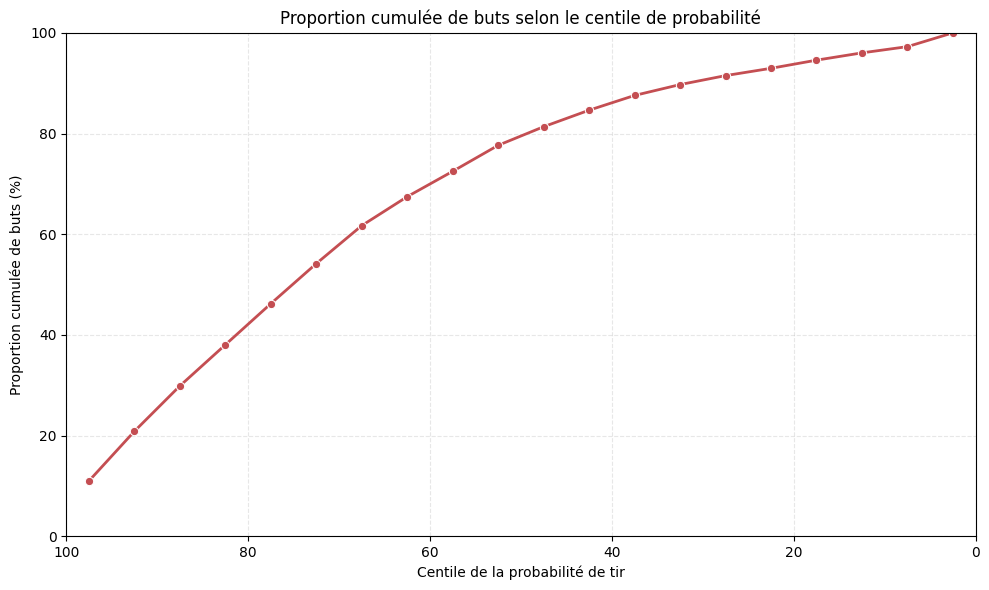

In [30]:
# On a besoin du nombre total de buts
total_goals = val_clean["is_goal"].sum()

# On fait comme au (ii) sauf que l'on prend la somme et non la moyenne de buts
cumulative_per_centile = (X_graph.groupby("centiles_bins", observed=True)["is_goal"].agg(["sum", "count"]).reset_index())

# On trie du plus haut centile
cumulative_per_centile = cumulative_per_centile.sort_values("centiles_bins", ascending=False)
cumulative_per_centile["cumulative_goals"] = cumulative_per_centile["sum"].cumsum()
cumulative_per_centile["cumulative_goal_rate"] = (cumulative_per_centile["cumulative_goals"] / total_goals) * 100

fig, ax = plt.subplots(figsize=(10, 6))

sns.lineplot(
    data=cumulative_per_centile,
    x="centiles_bins",
    y="cumulative_goal_rate",
    marker="o",
    color="#C44E52",
    linewidth=2,
    ax=ax
)
ax.set_title("Proportion cumulée de buts selon le centile de probabilité")
ax.set_xlabel("Centile de la probabilité de tir")
ax.invert_xaxis()
ax.set_xlim(100, 0) 
ax.set_ylabel("Proportion cumulée de buts (%)")
ax.set_ylim(0, 100)
ax.grid(True, linestyle="--", alpha=0.3)
plt.tight_layout()
plt.show()

On remarque qu'au début la courbe ne monte pas si vite que cela, ce qui fait en sorte que le modèle n'est pas si performant.

Passons maintenant au graphique (iv) qui est le diagramme de fiabilité.

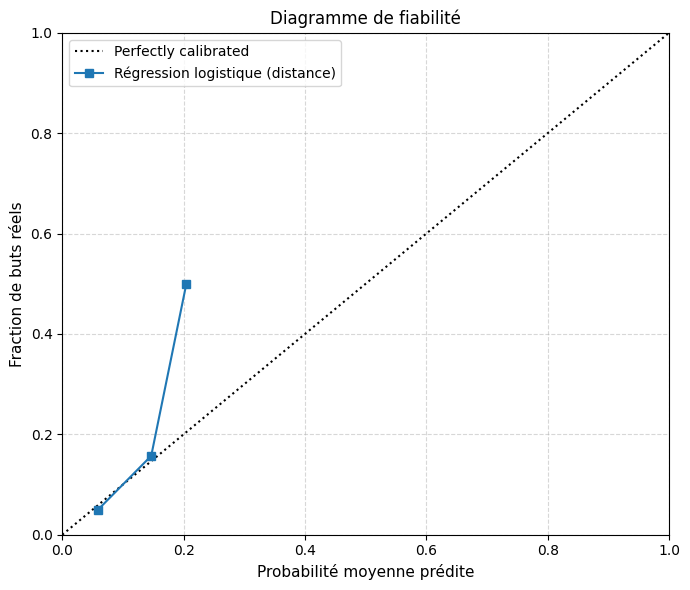

In [31]:
from IPython.core.pylabtools import figsize
from sklearn.calibration import calibration_curve, CalibrationDisplay

# Pour faire ce graphique on utilise la documentation sur https://scikit-learn.org/stable/modules/generated/sklearn.calibration.CalibrationDisplay.html

prob_true, prob_pred = calibration_curve(Y_val, Y_score_dist, n_bins=10)

fig, ax = plt.subplots(figsize=(7,6))
disp = CalibrationDisplay(prob_true, prob_pred, Y_score_dist)
disp.plot(ax=ax, name="Régression logistique (distance)")

ax.set_title("Diagramme de fiabilité", fontsize=12)
ax.set_xlabel("Probabilité moyenne prédite", fontsize=11)
ax.set_ylabel("Fraction de buts réels", fontsize=11)
ax.set_xlim(0, 1)
ax.set_ylim(0, 1)
ax.grid(True, linestyle="--", alpha=0.5)
ax.legend(loc="upper left")
plt.tight_layout()
plt.show()

Il est normal que la courbe ne va pas pas jusqu'à 1.0 sur l'axe des X car notre modèle de régression n'a pas prédit une probabilité plus haute que 0,5. D'un point de vue hockey, c'est normal puisque les tirs ont peu de chance d'être un but en général. Ce qui explique pourquoi la courbe est très haute pour x = 0.2, le modèle a attribué une probabilité d'autour de 0.2 pour la majorité des buts, ainsi, la fraction de buts réels est plus élevées.

## 3. D'autres modèles

Les 3 modèles soit :
- Régression logistique, entraînée sur la distance uniquement (déjà fait ci-dessus)
- Régression logistique, entraînée sur l'angle uniquement
- Régression logistique, entraînée sur la distance et l'angle

vont être entraînés et enregistrés dans un fichier à part (pour enregistrer l'expérience Wandb). Nous allons ensuite les utiliser ici pour générer les graphiques finaux. (le fichier est ici : \IFT3700_Projet1\ift6758\train_wandb\train_logistic_regression.py)

In [40]:
models_dir = PROJECT_ROOT / "models"
np.random.seed(42)
# Definition de nos ensemble de donnees
val_clean = val_all.dropna(subset=["shot_angle", "shot_distance", "is_goal"])
Y_val = val_clean["is_goal"]

# Charger nos modèles 
clf_dist = joblib.load(models_dir / "logreg_distance.joblib")
clf_angle = joblib.load(models_dir / "logreg_angle.joblib")
clf_dist_angle = joblib.load(models_dir / "logreg_distance_angle.joblib")

# Aller chercher le score de chaque modèle
score_dist = clf_dist.predict_proba(val_clean[["shot_distance"]])[:,1]
score_angle = clf_angle.predict_proba(val_clean[["shot_angle"]])[:,1]
score_dist_angle = clf_dist_angle.predict_proba(val_clean[["shot_distance", "shot_angle"]])[:,1]
score_random = np.random.uniform(0.0, 1.0, size=len(Y_val))

# Tout mettre dans un dictionnaire avec les couleurs
score_models = {
    "Distance": {
        "score": score_dist,
        "color": "blue"
    },
    "Angle": {
        "score": score_angle,
        "color": "green"  
    },
    "Distance + Angle": {
        "score": score_dist_angle,
        "color": "red" 
    },
    "Aléatoire": {
        "score": score_random,
        "color": "purple", 
        "linestyle": "--"
    }
}


Ici nous allons refaire les 4 graphiques que nous avions fait à l'étape 2, sauf que nous allons le faire avec les 4 modèles. Le code va se répéter, mais c'est pour que ce soit plus clair.

Graphique (i) de la courbe ROC et AUC. 
Le but est de mesurer la capacité des modèles à classifier un tir qui est un but avec une probabilité plus élevée qu'un tir qui n'est pas un but.

c:\Users\carig\Documents\GitHub\IFT3700_Projet1\.venv\lib\site-packages\sklearn\utils\_plotting.py:175: FutureWarning: `**kwargs` is deprecated and will be removed in 1.9. Pass all matplotlib arguments to `curve_kwargs` as a dictionary instead.
  warnings.warn(
c:\Users\carig\Documents\GitHub\IFT3700_Projet1\.venv\lib\site-packages\sklearn\utils\_plotting.py:175: FutureWarning: `**kwargs` is deprecated and will be removed in 1.9. Pass all matplotlib arguments to `curve_kwargs` as a dictionary instead.
  warnings.warn(
c:\Users\carig\Documents\GitHub\IFT3700_Projet1\.venv\lib\site-packages\sklearn\utils\_plotting.py:175: FutureWarning: `**kwargs` is deprecated and will be removed in 1.9. Pass all matplotlib arguments to `curve_kwargs` as a dictionary instead.
  warnings.warn(
c:\Users\carig\Documents\GitHub\IFT3700_Projet1\.venv\lib\site-packages\sklearn\utils\_plotting.py:175: FutureWarning: `**kwargs` is deprecated and will be removed in 1.9. Pass all matplotlib arguments to `curve_kw

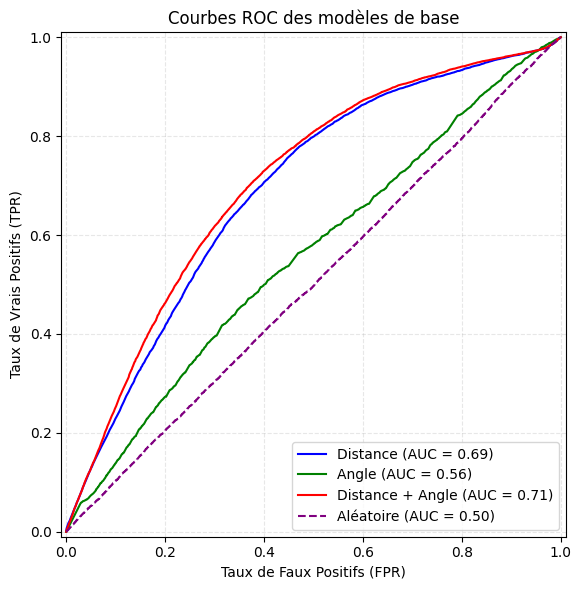

In [41]:
# Le code est inspiré des exemples de la documentation de sk-learn : https://scikit-learn.org/stable/auto_examples/model_selection/plot_roc.html

fig, ax = plt.subplots(figsize=(8,6))

for name, info in score_models.items():
    metrics.RocCurveDisplay.from_predictions(
        Y_val,
        info["score"],
        name=name,
        color=info["color"],
        ax=ax,
        linestyle=info.get("linestyle", "-")
    )

ax.set_title("Courbes ROC des modèles de base")
ax.set_xlabel("Taux de Faux Positifs (FPR)")
ax.set_ylabel("Taux de Vrais Positifs (TPR)")
ax.grid(True, linestyle="--", alpha=0.3)
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()